# Sprint 4 — The Ziv–Zakai bound, derived for this problem

**Sprint-4 deliverable:** a hand-derivation of the ZZB for BPSK delay estimation, and the intuition behind it.

**What and why.** Sprint 3 showed the CRLB fails below threshold because it is *local* (it only sees the curvature of
the true correlation peak) and *ignores the prior*. We need a bound on the MSE that

1. treats $\tau$ as **random** with a known prior (so "knowing nothing" gives a finite error), and
2. accounts for **large errors** — the estimator landing on a *distant* wrong delay.

The ZZB does both by an elegant idea: **turn estimation into many binary detection problems.** If an estimator could
locate $\tau$ to within $h/2$, it could tell "$\tau=\varphi$" from "$\tau=\varphi+h$". Detection theory tells us the
best possible error rate for that test, so it bounds how small the estimation error can be — for *every* separation
$h$, near or far.

## 4.1 The derivation, step by step

Throughout, $e=\hat\tau-\tau$ and $\tau$ has prior density $p(\varphi)$ (uniform on a window of width $T_a$).

### Step 1 — write the MSE as an integral of tail probabilities
For any non-negative random variable $X$, $\;\mathbb E[X^2]=\int_0^\infty 2x\,P(X\ge x)\,dx\;$ (integrate
$P(X\ge x)=\mathbb E[\mathbf 1\{X\ge x\}]$ against $2x$ and swap the order). Apply it to $X=|e|$ and substitute $x=h/2$:

$$ \text{MSE}=\mathbb E[e^2]=\int_0^\infty \frac h2\,P\!\left(|e|\ge \tfrac h2\right)dh. \tag{1}$$

*Meaning:* the MSE is a weighted sum, over all error sizes $h$, of "how often the error exceeds $h/2$".
Small errors and large errors both appear — this is what lets the bound see the threshold.

### Step 2 — split the tail probability into the two directions
$$ P(|e|\ge \tfrac h2)=\int p(\varphi)\,P(e\ge \tfrac h2\mid\tau=\varphi)\,d\varphi+\int p(\varphi)\,P(e\le -\tfrac h2\mid\tau=\varphi)\,d\varphi .$$
In the second integral substitute $\varphi\to\varphi+h$:

$$ P(|e|\ge \tfrac h2)=\int\Big[\,p(\varphi)\,P(e\ge\tfrac h2\mid\varphi)+p(\varphi+h)\,P(e\le-\tfrac h2\mid\varphi+h)\Big]d\varphi. \tag{2}$$

### Step 3 — recognise a binary detection problem
Fix $\varphi$ and $h$ and consider two hypotheses with prior weights proportional to $p(\varphi)$ and $p(\varphi+h)$:

$$ H_0:\ \tau=\varphi \qquad\text{vs}\qquad H_1:\ \tau=\varphi+h . $$

Use the estimator to decide: *choose $H_1$ if $\hat\tau\ge\varphi+h/2$, otherwise $H_0$.*
* Under $H_0$ this rule errs exactly when $\hat\tau\ge\varphi+h/2$, i.e. $e\ge h/2$.
* Under $H_1$ it errs exactly when $\hat\tau<\varphi+h/2$, i.e. $e<-h/2$.

So the bracket in (2) is $\big(p(\varphi)+p(\varphi+h)\big)\times$ (error probability of *this* detector). No
detector beats the optimal (minimum-error) one, whose error probability we call $P_{\min}(\varphi,\varphi+h)$:

$$ P(|e|\ge\tfrac h2)\ \ge\ \int\big(p(\varphi)+p(\varphi+h)\big)\,P_{\min}(\varphi,\varphi+h)\,d\varphi. \tag{3}$$

*Meaning:* **any** estimator, used as a detector, cannot beat the best detector — so its large-error probability is
bounded below.

### Step 4 — combine, and tighten by "valley filling"
Put (3) into (1):

$$ \text{MSE}\ \ge\ \frac12\int_0^\infty h\,\mathcal V\Big\{\int\big(p(\varphi)+p(\varphi+h)\big)P_{\min}(\varphi,\varphi+h)\,d\varphi\Big\}dh , \tag{4}$$

where $\mathcal V\{g\}(h)=\max_{\eta\ge0}g(h+\eta)$. The valley-filling operator is allowed because the left side of
(3) can only *decrease* with $h$, so it also exceeds every later value of the right side (Bell et al., 1997). For our
pilot the side-lobes are small and valley filling changes nothing numerically.

### Step 5 — the optimal detector for our signal
With equal priors (uniform prior), $H_0$ and $H_1$ are two **known signals in white Gaussian noise**,
$s_0=s(\cdot-\varphi)$ and $s_1=s(\cdot-\varphi-h)$. The optimal test compares the correlations of $\mathbf r$ with
$s_0$ and $s_1$; its statistic $T=\langle\mathbf r,s_1-s_0\rangle$ is Gaussian with means
$\langle s_0,s_1-s_0\rangle$ and $\langle s_1,s_1-s_0\rangle$ — a distance $\|s_1-s_0\|^2$ apart — and standard
deviation $\sigma\|s_1-s_0\|$. Thresholding halfway gives

$$ P_{\min}=Q\!\left(\frac{\|s_1-s_0\|}{2\sigma}\right),\qquad Q(x)=\int_x^\infty\tfrac{1}{\sqrt{2\pi}}e^{-u^2/2}du. $$

Now $\|s_1-s_0\|^2=\|s_0\|^2+\|s_1\|^2-2\langle s_0,s_1\rangle=2\sum_n s^2\,\big(1-\rho(h)\big)$, and
$\sum_n s^2/(2\sigma^2)=E/N_0$ (Sprint 0), so

$$ \boxed{P_{\min}(h)=Q\!\left(\sqrt{\tfrac{E}{N_0}\,\big(1-\rho(h)\big)}\right)} \tag{5}$$

*Meaning:* two delays are hard to tell apart when the signal is weak (small $E/N_0$) **or** when the two shifted
signals look alike ($\rho(h)$ close to 1, i.e. $h$ inside the main lobe or on a side-lobe).

### Step 6 — the uniform prior
$P_{\min}$ does not depend on $\varphi$ (shift invariance, verified to ~$2\cdot10^{-5}$). Both $\varphi$ and $\varphi+h$
must lie in the window, which is true for a range of $\varphi$ of length $T_a-h$, each density being $1/T_a$:

$$ \int\big(p(\varphi)+p(\varphi+h)\big)d\varphi=\frac{2(T_a-h)}{T_a}=2\Big(1-\frac h{T_a}\Big),\qquad 0\le h\le T_a. $$

### Result
$$ \boxed{\;\text{ZZB}=\int_0^{T_a} h\;\mathcal V\Big\{\Big(1-\frac{h}{T_a}\Big)\,Q\!\Big(\sqrt{\tfrac{E}{N_0}\,(1-\rho(h))}\Big)\Big\}\,dh\;} $$

## 4.2 Sanity of the result: the two limits (proved analytically)

**No signal ($E/N_0\to0$).** $Q(0)=\tfrac12$, so

$$ \text{ZZB}\to\int_0^{T_a}\frac h2\Big(1-\frac h{T_a}\Big)dh=\frac{T_a^2}{4}-\frac{T_a^2}{6}=\frac{T_a^2}{12}, $$

the variance of the prior. No estimator can do better than this without data, and "answer the window centre"
achieves it. The bound is **finite**, unlike the CRLB.

**Strong signal ($E/N_0\to\infty$).** Only small $h$ matter (otherwise $Q(\cdot)\approx0$). For small $h$,
$1-\rho(h)\approx\tfrac12\beta^2h^2$ (because $\rho''(0)=-\beta^2$) and $1-h/T_a\approx1$, so with
$a^2=\tfrac12\tfrac{E}{N_0}\beta^2$:

$$ \text{ZZB}\to\int_0^\infty h\,Q(ah)\,dh=\frac{1}{4a^2}=\frac{1}{2\,(E/N_0)\,\beta^2}=\text{CRLB}. $$

(The integral: integrate by parts, $\int_0^\infty hQ(ah)dh=\tfrac a2\int_0^\infty h^2\phi(ah)dh=\tfrac1{2a^2}\int_0^\infty u^2\phi(u)du=\tfrac1{4a^2}$.)

So the ZZB **reduces to the CRLB at high SNR and to the prior variance at low SNR**, and in between it must rise as
distant delays become confusable — exactly the threshold behaviour.

In [1]:
# --- setup: import the project's small core library (../sdet) -------------
import sys, inspect
sys.path.insert(0, "..")
import numpy as np
from sdet import *
from sdet.style import COLORS, INK2, MUTED, apply_style, plt
%matplotlib inline
apply_style()
FIG = "../figures/"     # figures are also saved here for slides
DATA = "../data/"       # small result files shared between notebooks

## 4.3 Intuition in pictures

We plot, for our pilot, the ingredients of the integral at three SNRs:
* left: $P_{\min}(h)$ — how often the best detector confuses delays $h$ apart;
* right: the integrand $h\,(1-h/T_a)\,P_{\min}(h)$ — which separations $h$ contribute to the bound.

At high SNR only small $h$ contribute (a local, CRLB-like picture). At low SNR large separations — far outside the
main lobe — contribute heavily: these are the gross errors the CRLB cannot see.

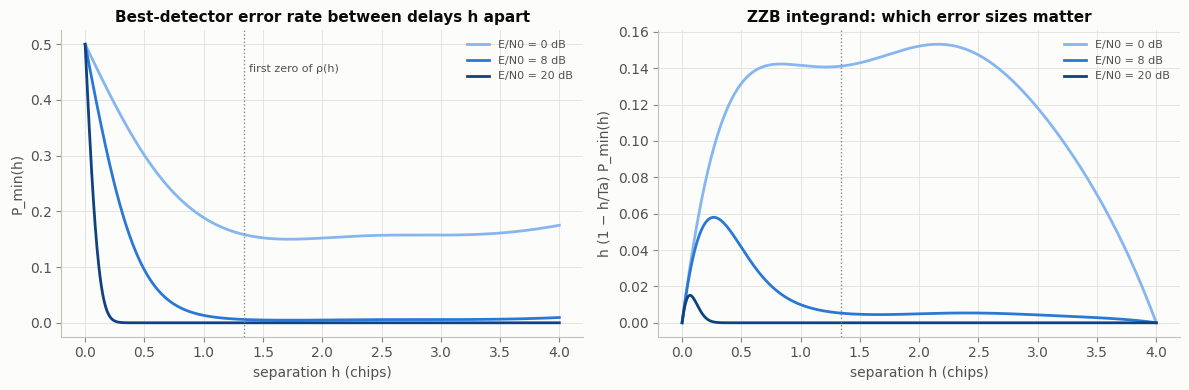

In [2]:
cfg = Config()
sc = BatchScenario(cfg, np.random.default_rng(cfg.seed))
ta = cfg.prior_width
h = np.linspace(0, ta, 801)
rho = autocorrelation(sc, h)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for color, db in zip(["#86b6ef", "#2a78d6", "#104281"], (0, 8, 20)):
    pmin = qfunc(np.sqrt(10 ** (db / 10) * np.clip(1 - rho, 0, None)))
    ax[0].plot(h, pmin, color=color, label=f"E/N0 = {db} dB")
    ax[1].plot(h, h * (1 - h / ta) * pmin, color=color, label=f"E/N0 = {db} dB")
ax[0].set_xlabel("separation h (chips)"); ax[0].set_ylabel("P_min(h)")
ax[0].set_title("Best-detector error rate between delays h apart")
ax[1].set_xlabel("separation h (chips)"); ax[1].set_ylabel("h (1 − h/Ta) P_min(h)")
ax[1].set_title("ZZB integrand: which error sizes matter")
for a in ax:
    a.axvline(1.34, color=MUTED, ls=":", lw=1)
    a.legend(loc="upper right", fontsize=8)
ax[0].text(1.38, 0.45, "first zero of ρ(h)", color=INK2, fontsize=8)
fig.tight_layout(); fig.savefig(FIG + "s4_zzb_intuition.png")

## 4.4 How to explain the ZZB simply (for the professor)

> "Suppose you had an estimator that is usually within half a chip. Then you could use it as a detector to tell
> 'delay = φ' from 'delay = φ + 1 chip'. But detection theory says how often *any* detector must confuse those two —
> that depends only on the SNR and on how similar the two shifted signals are (their correlation ρ). So the estimator
> must make errors of about that size at least that often. Doing this for every separation h and adding up gives a
> lower bound on the MSE. At high SNR only tiny separations are ever confused, and you recover the CRLB; at low SNR
> even far-apart delays get confused, and the bound rises — that is the threshold. And with no signal at all, the
> bound is the prior variance, because you can't do better than knowing the window."

---
## 4.5 Numerical evaluation of the ZZB (Sprint-5 material, done early)

The sprint plan puts *coding* the ZZB in Sprint 5. It is already implemented (`sdet/bounds.py: zzb`, ~10 lines: build
$\rho(h)$ on a fine grid, evaluate the integrand, valley-fill with a reversed running maximum, integrate with the
trapezoid rule). It is included here because **a derivation is much easier to defend when you can show it reproduces
its own limits and sits correctly against simulation.**

**Is it required now?** Not by the sprint plan. **Is it useful?** Yes: it turns the Sprint-4 derivation into a checked
result, and it is the first half of the Sprint-5 four-curve plot.

In [3]:
print(inspect.getsource(zzb))

def zzb(scenario, en0, n_h=8001):
    """Ziv-Zakai bound (Bell et al. 1997, scalar, with valley filling) for
    tau ~ U[0, Ta]:

        MSE >= int_0^Ta  h * V{ (1 - h/Ta) * Pmin(h) } dh,
        Pmin(h) = Q( sqrt( (E/N0) * (1 - rho(h)) ) ),

    where Pmin(h) is the minimum error probability of the binary test
    'tau = phi' vs 'tau = phi + h' (equally likely, known signals, AWGN), and
    V{f}(h) = max_{eta >= 0} f(h + eta) is the valley-filling operator.
    rho(h) is treated as independent of phi (verified: varies by ~2e-5).
    With the smoothly truncated pulse, ZZB/CRLB -> 0.997 at 40 dB (converged in
    n_h). Valley filling is numerically inactive for this pilot (sidelobes
    |rho| <= 0.13), changing the ZZB by < 0.01 %.
    """
    ta = scenario.cfg.prior_width
    h = np.linspace(0.0, ta, n_h)
    one_minus_rho = np.clip(1.0 - autocorrelation(scenario, h), 0.0, None)
    en0 = np.atleast_1d(np.asarray(en0, dtype=float))
    f = (1.0 - h / ta)[None, :] * qfunc(np.sqrt(en0[:

low-SNR limit:  ZZB = 1.3323   vs  Ta^2/12 = 1.3333
high-SNR limit: ZZB / CRLB at 40 dB = 0.9971   (-> 1)


ZZB first exceeds 2 x CRLB (3 dB) at about 5.9 dB (scanning down from high SNR)


ZZB below the MLE's 95 % CI upper limit at every SNR: True
smallest MSE/ZZB ratio: 0.972 (values just below 1 at high SNR are Monte Carlo scatter)


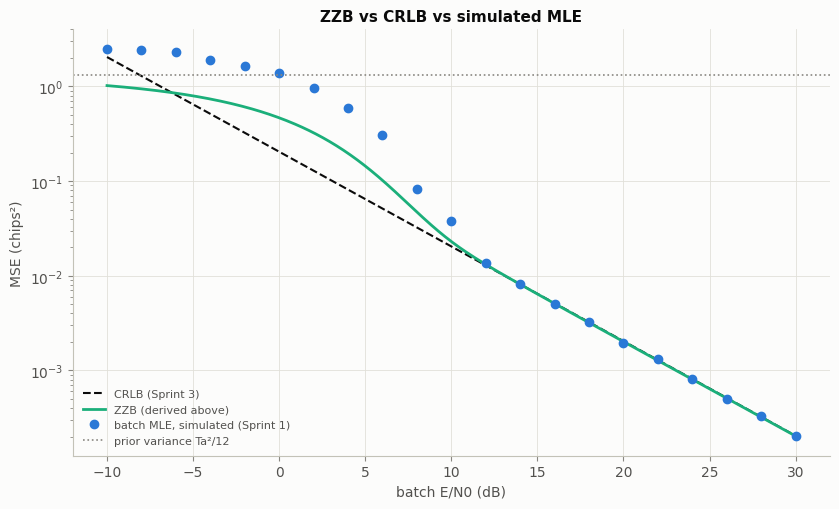

In [4]:
lo, hi = zzb(sc, [1e-6, 1e4])
print(f"low-SNR limit:  ZZB = {lo:.4f}   vs  Ta^2/12 = {prior_variance(cfg):.4f}")
print(f"high-SNR limit: ZZB / CRLB at 40 dB = {hi / crlb(sc, 1e4):.4f}   (-> 1)")

d = np.load(DATA + "s1_mle.npz")                     # the Sprint-1 Monte Carlo data
snr_db, err = d["snr_db"], d["err"]
xf = np.linspace(-10, 30, 400)
z, c = zzb(sc, 10 ** (xf / 10)), crlb(sc, 10 ** (xf / 10))

fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.semilogy(xf, c, color=COLORS["crlb"], ls="--", lw=1.5, label="CRLB (Sprint 3)")
ax.semilogy(xf, z, color=COLORS["zzb"], lw=2, label="ZZB (derived above)")
ax.semilogy(snr_db, np.mean(err ** 2, 1), "o", color=COLORS["mle"], label="batch MLE, simulated (Sprint 1)")
ax.axhline(prior_variance(cfg), color=COLORS["prior"], ls=":", lw=1.2, label="prior variance Ta²/12")
ax.set_xlabel("batch E/N0 (dB)"); ax.set_ylabel("MSE (chips²)")
ax.set_title("ZZB vs CRLB vs simulated MLE")
ax.legend(loc="lower left", fontsize=8)
fig.tight_layout(); fig.savefig(FIG + "s4_zzb_vs_crlb_vs_mle.png")

# scan DOWN from high SNR: the highest SNR at which the ZZB exceeds 2 x CRLB
thr_zzb = xf[np.where(z / c > 2)[0].max()]
print(f"ZZB first exceeds 2 x CRLB (3 dB) at about {thr_zzb:.1f} dB (scanning down from high SNR)")

# A valid bound must lie below the simulated MSE. The simulation has Monte Carlo error (2000 trials), so we test
# whether the bound is below the upper end of the 95 % confidence interval of the MSE at every SNR.
mse_s = np.mean(err ** 2, 1)
upper = mse_s + 1.96 * np.std(err ** 2, 1) / np.sqrt(err.shape[1])
zz_s = zzb(sc, 10 ** (snr_db / 10))
print("ZZB below the MLE's 95 % CI upper limit at every SNR:", bool(np.all(zz_s <= upper)))
print(f"smallest MSE/ZZB ratio: {np.min(mse_s / zz_s):.3f} (values just below 1 at high SNR are Monte Carlo scatter)")

### What this shows
* The numerical ZZB reproduces **both analytical limits** (prior variance at low SNR, CRLB at high SNR), so the
  implementation matches the derivation.
* The ZZB **bends away from the CRLB** below about 6 dB and stays **below the simulated MLE everywhere**, as a valid
  bound must.
* The MLE's own break-away is about **3 dB later** (≈ 9–10 dB). Why the gap? Two separate reasons, both explored in
  notebook 05: (i) the ZZB bounds the *best possible* estimator (the posterior mean, "MMSE"), and the MLE is not that
  estimator — e.g. on pure noise the MLE's MSE is 3.1 chips² while the best estimator's is 1.33; (ii) the ZZB is built
  from *pairwise* tests, while an estimator must beat *all* competing delays at once. Notebook 05 shows that at low
  SNR reason (i) dominates, but around the threshold reason (ii) does: even the MMSE breaks away only ≈ 0.9 dB earlier
  than the MLE (precise study, notebook 06: MMSE 8.54 dB, MLE 9.52 dB, ZZB 5.95 dB). The size of the gap also
  depends on the pilot (MLE − ZZB 2.7–5.4 dB over 5 random pilots, notebook 06).

## 4.6 What Sprint 4 gives the next stages
A derived, verified ZZB for exactly our model. Sprint 5 adds the DLL to the comparison (four curves on one plot), and
Sprint 6 locates the thresholds precisely and explains the DLL-vs-MLE difference. Both are already done — see
notebook 05.